In [12]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mtalaltariq/paysim-data/paysim dataset.csv


In [13]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE
 
DATA_PATH = "/kaggle/input/datasets/mtalaltariq/paysim-data/paysim dataset.csv"
df = pd.read_csv(DATA_PATH)
 
print("Shape:", df.shape)
print(df.info())
print("\nFraud distribution:")
print(df['isFraud'].value_counts())
print("\nFraud ratio (%):", df['isFraud'].mean() * 100)

Shape: (6362620, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
None

Fraud distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud ratio (%): 0.12908204481801522


In [14]:

df_model = df.drop(columns=["nameOrig", "nameDest", "isFlaggedFraud"])

feature_cols = [
    "step", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest",
    "type_CASH_OUT", "type_DEBIT", "type_PAYMENT", "type_TRANSFER"
]

type_dummies = pd.get_dummies(
    df_model["type"], prefix="type"
).reindex(
    columns=[
        "type_CASH_OUT", "type_DEBIT",
        "type_PAYMENT", "type_TRANSFER"
    ],
    fill_value=0
).astype(int)

df_model = pd.concat(
    [df_model.drop(columns=["type"]), type_dummies],
    axis=1
)

X = df_model[feature_cols]
y = df_model["isFraud"]

print("Feature columns:", feature_cols)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Transaction type encoding:")
print(type_dummies.sum())


Feature columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
X shape: (6362620, 10)
y shape: (6362620,)
Transaction type encoding:
type_CASH_OUT    2237500
type_DEBIT         41432
type_PAYMENT     2151495
type_TRANSFER     532909
dtype: int64


In [15]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Before SMOTE:", y_train.value_counts().to_dict())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("After SMOTE:", pd.Series(y_train_res).value_counts().to_dict())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)   
X_test_scaled = scaler.transform(X_test)             


Before SMOTE: {0: 5083526, 1: 6570}
After SMOTE: {0: 5083526, 1: 5083526}


In [26]:

import joblib
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    brier_score_loss
)
from imblearn.over_sampling import SMOTE

# Split the training data into model-training and calibration sets
X_fit, X_cal, y_fit, y_cal = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

# Apply SMOTE only to the model-training data
smote = SMOTE(random_state=42)
X_fit_res, y_fit_res = smote.fit_resample(X_fit, y_fit)

# Scale using the resampled training data
scaler = StandardScaler()
X_fit_scaled = scaler.fit_transform(X_fit_res)

# Train the base Decision Tree
base_model = DecisionTreeClassifier(random_state=42)
base_model.fit(X_fit_scaled, y_fit_res)

# Calibrate using the untouched, naturally imbalanced calibration set
X_cal_scaled = scaler.transform(X_cal)
calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(base_model),
    method="sigmoid"
)
calibrated_model.fit(X_cal_scaled, y_cal)

# Evaluate on the untouched test set
X_test_scaled = scaler.transform(X_test)
y_test_prob = calibrated_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("Calibrated Decision Tree")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))
print("Average Precision:", average_precision_score(y_test, y_test_prob))
print("Brier Score:", brier_score_loss(y_test, y_test_prob))
print("Sample fraud probabilities:", y_test_prob[:10])

# Save the calibrated model and its matching scaler
joblib.dump(calibrated_model, "fraud_model.pkl")
joblib.dump(scaler, "scaler.pkl")

# Save the feature names and background data for LIME
feature_names = list(X_train.columns)
background_data = X_fit_res[feature_names].sample(
    n=min(2000, len(X_fit_res)),
    random_state=42
).to_numpy()

joblib.dump(feature_names, "feature_names.pkl")
joblib.dump(background_data, "explain_background.pkl")

print("Saved calibrated model, scaler, feature names, and LIME data.")


Calibrated Decision Tree
Confusion Matrix:
[[1270167     714]
 [     83    1560]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.69      0.95      0.80      1643

    accuracy                           1.00   1272524
   macro avg       0.84      0.97      0.90   1272524
weighted avg       1.00      1.00      1.00   1272524

Average Precision: 0.6514253565167383
Brier Score: 0.00045062065155782033
Sample fraud probabilities: [6.68679629e-05 6.68679629e-05 6.68679629e-05 6.68679629e-05
 6.68679629e-05 6.68679629e-05 6.68679629e-05 6.68679629e-05
 6.68679629e-05 6.68679629e-05]
Saved calibrated model, scaler, feature names, and LIME data.


In [27]:

import numpy as np

print("Probability distribution:")
print(np.percentile(
    y_test_prob,
    [0, 25, 50, 75, 90, 95, 99, 99.9, 100]
))

print("\nNumber of unique probabilities:",
      len(np.unique(y_test_prob)))

print("\nProbability ranges:")
for low, high in [(0, 0.01), (0.01, 0.1),
                  (0.1, 0.3), (0.3, 0.5),
                  (0.5, 0.7), (0.7, 0.9),
                  (0.9, 1.0)]:
    count = np.sum((y_test_prob >= low) &
                   (y_test_prob < high))
    if high == 1.0:
        count += np.sum(y_test_prob == 1.0)
    print(f"{low:.2f}–{high:.2f}: {count}")


Probability distribution:
[6.68679629e-05 6.68679629e-05 6.68679629e-05 6.68679629e-05
 6.68679629e-05 6.68679629e-05 6.68679629e-05 6.69561008e-01
 6.69561008e-01]

Number of unique probabilities: 2

Probability ranges:
0.00–0.01: 1270250
0.01–0.10: 0
0.10–0.30: 0
0.30–0.50: 0
0.50–0.70: 2274
0.70–0.90: 0
0.90–1.00: 0


In [28]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    brier_score_loss
)
import numpy as np
import joblib

# Use the ORIGINAL fitted Decision Tree
# and the same scaler as the original model.
X_cal_scaled = scaler.transform(X_cal)
X_test_scaled = scaler.transform(X_test)

isotonic_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(best_model),
    method="isotonic"
)
isotonic_model.fit(X_cal_scaled, y_cal)

prob = isotonic_model.predict_proba(X_test_scaled)[:, 1]
pred = (prob >= 0.5).astype(int)

print(classification_report(y_test, pred))
print("Average precision:", average_precision_score(y_test, prob))
print("Brier score:", brier_score_loss(y_test, prob))
print("Unique probabilities:", len(np.unique(prob)))
print("Percentiles:", np.percentile(
    prob, [0, 25, 50, 75, 90, 95, 99, 99.9, 100]
))

joblib.dump(isotonic_model, "fraud_model_isotonic.pkl")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Average precision: 0.07405927208678861
Brier score: 0.0011957488991689723
Unique probabilities: 2
Percentiles: [0.0010634  0.0010634  0.0010634  0.0010634  0.0010634  0.0010634
 0.0010634  0.0010634  0.43773585]


['fraud_model_isotonic.pkl']

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200, use_label_encoder=False,
        eval_metric="logloss", random_state=42
    ),
}

trained_models = {}

for name, clf in models.items():
    print(f"Training {name} ...")
    clf.fit(X_train_scaled, y_train_res)
    trained_models[name] = clf

print("\nAll models trained.")

Training Logistic Regression ...
Training Random Forest ...
Training Decision Tree ...
Training XGBoost ...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:56:25] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



All models trained.


In [17]:
results = []
roc_data = {}
conf_matrices = {}

for name, clf in trained_models.items():
    y_pred = clf.predict(X_test_scaled)
    y_proba = clf.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    conf_matrices[name] = cm
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, auc)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    print(f"\n===== {name} =====")
    print(f"Recall (fraud catch rate): {rec:.4f}  <-- operational priority")
    print(classification_report(y_test, y_pred, digits=4))
    print("Confusion Matrix:\n", cm)



===== Logistic Regression =====
Recall (fraud catch rate): 0.9580  <-- operational priority
              precision    recall  f1-score   support

           0     0.9999    0.9528    0.9758   1270881
           1     0.0256    0.9580    0.0499      1643

    accuracy                         0.9528   1272524
   macro avg     0.5128    0.9554    0.5128   1272524
weighted avg     0.9987    0.9528    0.9746   1272524

Confusion Matrix:
 [[1210949   59932]
 [     69    1574]]

===== Random Forest =====
Recall (fraud catch rate): 0.9519  <-- operational priority
              precision    recall  f1-score   support

           0     0.9999    0.9994    0.9997   1270881
           1     0.6768    0.9519    0.7911      1643

    accuracy                         0.9994   1272524
   macro avg     0.8384    0.9757    0.8954   1272524
weighted avg     0.9995    0.9994    0.9994   1272524

Confusion Matrix:
 [[1270134     747]
 [     79    1564]]

===== Decision Tree =====
Recall (fraud catch rat

In [18]:
results_df = pd.DataFrame(results).set_index("Model")
results_df = results_df.sort_values(by="Recall", ascending=False)

print("Model Comparison Table:")
display(results_df.round(4))

Model Comparison Table:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
XGBoost,0.9988,0.5157,0.9884,0.6778,0.9996
Decision Tree,0.9994,0.7093,0.9610,0.8162,0.9803
Logistic Regression,0.9528,0.0256,0.9580,0.0499,0.9903
Random Forest,0.9994,0.6768,0.9519,0.7911,0.9989


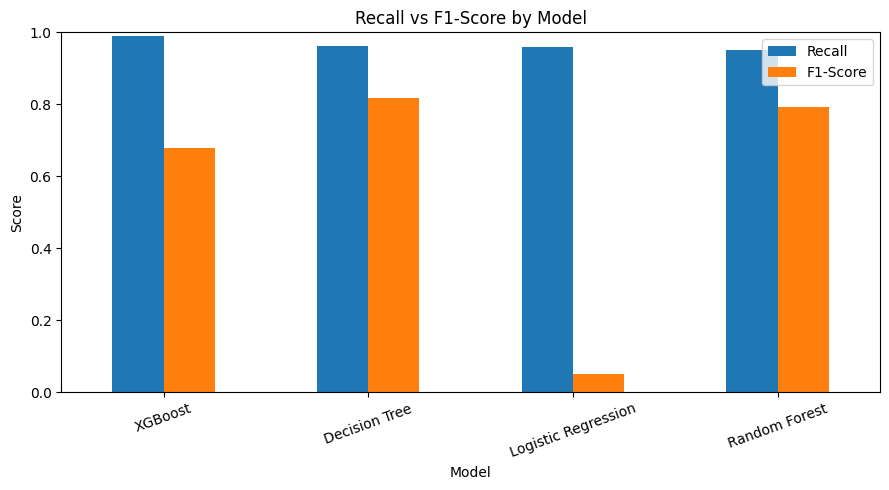

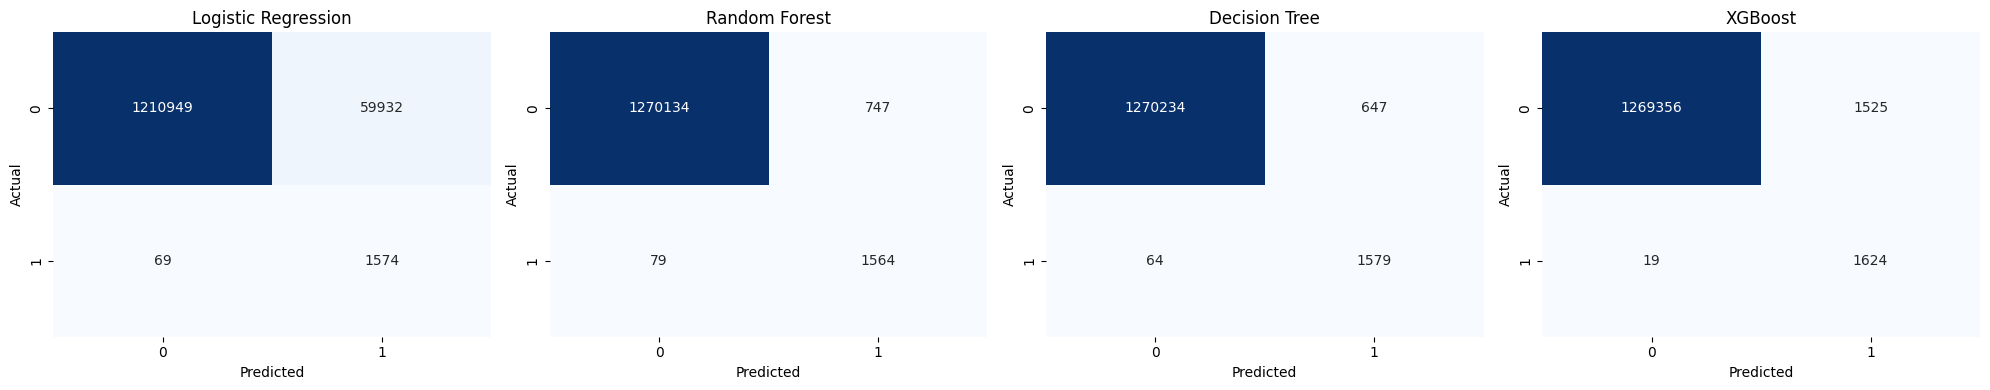

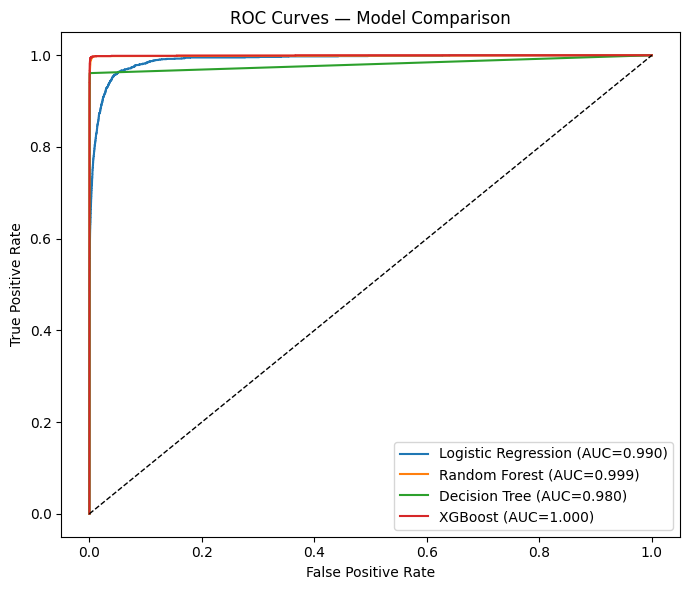

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
results_df[["Recall", "F1-Score"]].plot(kind="bar", ax=ax)
plt.title("Recall vs F1-Score by Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(conf_matrices), figsize=(5 * len(conf_matrices), 4))
for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
results_df["Rank_Score"] = results_df["Recall"] * 0.7 + results_df["F1-Score"] * 0.3
best_model_name = results_df["Rank_Score"].idxmax()
best_model = trained_models[best_model_name]

print(f"Best model selected: {best_model_name}")
print(results_df.loc[best_model_name])

joblib.dump(best_model, "fraud_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("\nSaved fraud_model.pkl and scaler.pkl to /kaggle/working/")
print("Download both from the Output panel (top-right after running) and")
print("drop them into your Streamlit app folder alongside app.py.")
print("Feature order is unchanged, so app.py requires no code changes.")

Best model selected: Decision Tree
Accuracy      0.999441
Precision     0.709344
Recall        0.961047
F1-Score      0.816232
ROC-AUC       0.980269
Rank_Score    0.917602
Name: Decision Tree, dtype: float64

Saved fraud_model.pkl and scaler.pkl to /kaggle/working/
Download both from the Output panel (top-right after running) and
drop them into your Streamlit app folder alongside app.py.
Feature order is unchanged, so app.py requires no code changes.


In [21]:

feature_names = feature_cols

background_data = X_train_res[feature_cols].sample(
    n=min(2000, len(X_train_res)),
    random_state=42
).to_numpy()

joblib.dump(background_data, "explain_background.pkl")
joblib.dump(feature_names, "feature_names.pkl")

print("Saved files for fraud detection and Explainable AI:")
print("fraud_model.pkl")
print("scaler.pkl")
print("explain_background.pkl")
print("feature_names.pkl")


Saved files for fraud detection and Explainable AI:
fraud_model.pkl
scaler.pkl
explain_background.pkl
feature_names.pkl


In [22]:

from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

y_test_prob = best_model.predict_proba(X_test_scaled)[:, list(best_model.classes_).index(1)]
y_test_pred = best_model.predict(X_test_scaled)

print("Selected model:", best_model_name)
print("Model classes:", best_model.classes_)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

print("Average Precision:", average_precision_score(y_test, y_test_prob))
print("Actual fraud cases in test set:", int((y_test == 1).sum()))
print("Fraud cases predicted:", int((y_test_pred == 1).sum()))
print("Highest fraud probability:", round(y_test_prob.max(), 6))


Selected model: Decision Tree
Model classes: [0 1]

Confusion Matrix:
[[1270234     647]
 [     64    1579]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.71      0.96      0.82      1643

    accuracy                           1.00   1272524
   macro avg       0.85      0.98      0.91   1272524
weighted avg       1.00      1.00      1.00   1272524

Average Precision: 0.6817632320257309
Actual fraud cases in test set: 1643
Fraud cases predicted: 2226
Highest fraud probability: 1.0


In [23]:

test_input = pd.DataFrame([{
    "step": 100,
    "amount": 100000,
    "oldbalanceOrg": 100000,
    "newbalanceOrig": 0,
    "oldbalanceDest": 50000,
    "newbalanceDest": 50000,
    "type_CASH_OUT": 1,
    "type_DEBIT": 0,
    "type_PAYMENT": 0,
    "type_TRANSFER": 0
}], columns=feature_cols)

test_scaled = scaler.transform(test_input)
test_probabilities = best_model.predict_proba(test_scaled)

fraud_index = list(best_model.classes_).index(1)
fraud_probability = test_probabilities[0, fraud_index]

print("Model:", best_model_name)
print("Class probabilities:", test_probabilities)
print("Fraud probability:", round(fraud_probability, 6))
print("Fraud risk score:", round(fraud_probability * 100, 2), "/100")


Model: Decision Tree
Class probabilities: [[1. 0.]]
Fraud probability: 0.0
Fraud risk score: 0.0 /100


In [24]:

test_results = X_test.copy()
test_results["actual"] = y_test
test_results["predicted"] = y_test_pred
test_results["fraud_probability"] = y_test_prob

correct_frauds = test_results[
    (test_results["actual"] == 1) &
    (test_results["predicted"] == 1)
].sort_values("fraud_probability", ascending=False)

print("Correctly detected fraud examples:")
print(correct_frauds.head(5).to_string(index=False))


Correctly detected fraud examples:
 step     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  actual  predicted  fraud_probability
  629   19527.35       19527.35             0.0       676072.20       695599.55              1           0             0              0       1          1                1.0
  583  759701.03      759701.03             0.0      1076095.67      1835796.71              1           0             0              0       1          1                1.0
   22  235512.20      235512.20             0.0            0.00            0.00              0           0             0              1       1          1                1.0
    9 2539898.07     2539898.07             0.0            0.00       261290.69              0           0             0              1       1          1                1.0
  446 7782452.17     7782452.17             0.0            0.00      7782452.17              1 

In [25]:
# Get genuine and fraud examples from the test dataset
test_results = X_test.copy()
test_results["actual"] = y_test
test_results["predicted"] = y_test_pred
test_results["fraud_probability"] = y_test_prob

# Show 5 correctly classified genuine transactions
print("GENUINE TRANSACTIONS")
print(test_results[
    (test_results["actual"] == 0) &
    (test_results["predicted"] == 0)
].head(5).to_string(index=False))

# Show 5 correctly classified fraud transactions
print("\nFRAUD TRANSACTIONS")
print(test_results[
    (test_results["actual"] == 1) &
    (test_results["predicted"] == 1)
].head(5).to_string(index=False))

GENUINE TRANSACTIONS
 step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  actual  predicted  fraud_probability
  300 890577.21         218.00            0.00            0.00       890577.21              0           0             0              1       0          0                0.0
  399  97734.24     2096258.84      2193993.08       320136.00       222401.76              0           0             0              0       0          0                0.0
  718   5907.41         315.00            0.00            0.00            0.00              0           0             1              0       0          0                0.0
  186 187696.30       11057.00            0.00      1798095.21      1985791.51              1           0             0              0       0          0                0.0
  331  82646.52           0.00            0.00      1047805.87      1130452.39              1           0         